In [1]:
import os
from pathlib import Path

def get_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, current.parent, current.parent.parent]:
        if (candidate / "data" / "raw").exists() or (candidate / "requirements.txt").exists():
            return candidate
    return current

PROJECT_ROOT = get_project_root()
os.chdir(PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

# Safe Google Colab import
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    files = None

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Plot settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
import os
from pathlib import Path
import pandas as pd

# Load dataset using robust local workspace or Colab path
raw_file = PROJECT_ROOT / "data" / "raw" / "Student Performance Factors.csv"
if not raw_file.exists() and os.path.exists("/content/Student Performance Factors.csv"):
    raw_file = Path("/content/Student Performance Factors.csv")

df = pd.read_csv(raw_file)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully.
Dataset shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [3]:
display(df.tail())

display(df.sample(5, random_state=42))

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
743,20,71,Medium,Low,No,7,87,High,Yes,1,Medium,Medium,Public,Negative,5,No,High School,Near,Male,65
5551,22,71,Medium,Low,Yes,7,98,Low,Yes,2,Low,High,Public,Neutral,2,No,High School,Moderate,Female,65
3442,21,91,High,Medium,Yes,6,53,High,Yes,1,Medium,Medium,Public,Positive,3,No,Postgraduate,Near,Female,71
6571,12,91,Medium,Low,Yes,8,81,Low,Yes,0,Low,Low,Public,Positive,4,No,High School,Moderate,Male,64
4204,21,63,Low,High,Yes,8,95,Medium,Yes,2,High,Medium,Public,Neutral,5,No,High School,Near,Male,66


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape:
(6607, 20)

Column Names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Data Types:
Hours_Studied                 int64
Attendance                    int64
Parental_Involvement            str
Access_to_Resources             str
Extracurricular_Activities      str
Sleep_Hours                   int64
Previous_Scores               int64
Motivation_Level                str
Internet_Access                 str
Tutoring_Sessions             int64
Family_Income                   str
Teacher_Quality                 str
School_Type                     str
Peer_Influence                  str
Physical_Activity             int64
Learning_Disab

In [5]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


,Missing_Count,Missing_Percentage
Teacher_Quality,78,1.18
Parental_Education_Level,90,1.36
Distance_from_Home,67,1.01


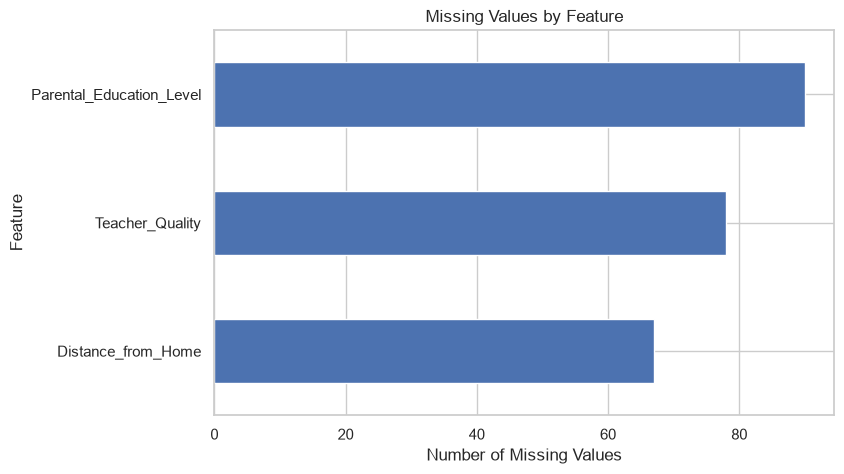

In [6]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing = missing[missing["Missing_Count"] > 0]

display(missing)

plt.figure(figsize=(8, 5))

missing["Missing_Count"].sort_values().plot(kind="barh")

plt.title("Missing Values by Feature")
plt.xlabel("Number of Missing Values")
plt.ylabel("Feature")

plt.show()

In [7]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

if duplicate_count == 0:
    print("No duplicate records found.")
else:
    print("Duplicate records require investigation.")

Number of duplicate rows: 0
No duplicate records found.


In [8]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Categorical Columns:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


C:\Users\mansi\AppData\Local\Temp\ipykernel_14580\3824244136.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [9]:
target = "Exam_Score"
print("Target Variable:", target)

print("\nTarget Statistics:")
display(df[target].describe())

Target Variable: Exam_Score

Target Statistics:


count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

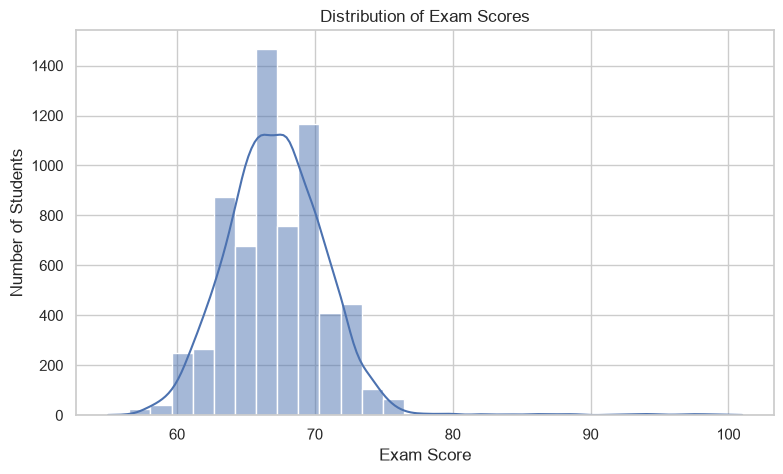

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df["Exam_Score"],
    bins=30,
    kde=True
)

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()

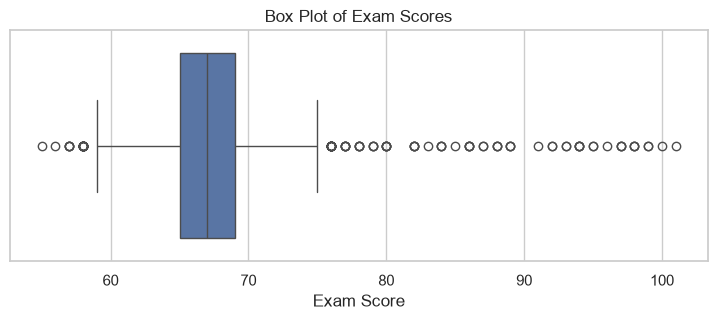

In [11]:
plt.figure(figsize=(9, 3))

sns.boxplot(x=df["Exam_Score"])

plt.title("Box Plot of Exam Scores")
plt.xlabel("Exam Score")

plt.show()

In [12]:
score_101 = df[df["Exam_Score"] == 101]

print("Number of records with Exam_Score = 101:")
print(len(score_101))

display(score_101)

Number of records with Exam_Score = 101:
1


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


In [13]:
df.loc[df["Exam_Score"] > 100, "Exam_Score"] = 100
print("Adjusted Exam_Score outliers. New maximum score:", df["Exam_Score"].max())

Adjusted Exam_Score outliers. New maximum score: 100


['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']


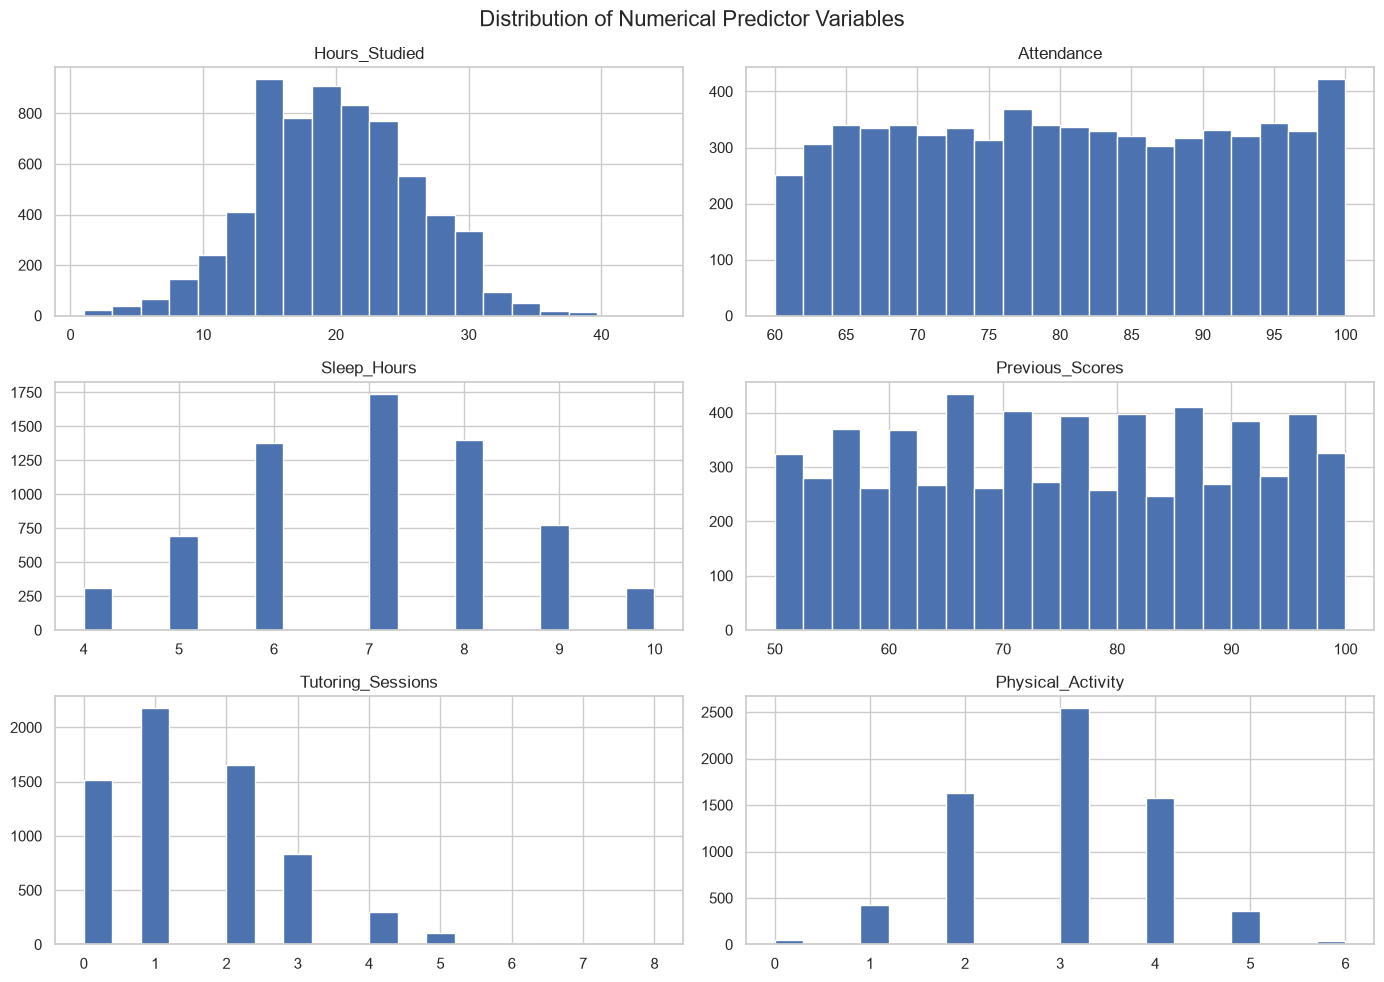

In [14]:
numerical_predictors = [
    col for col in numerical_columns
    if col != target
]

print(numerical_predictors)

df[numerical_predictors].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle(
    "Distribution of Numerical Predictor Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()

Exam_Score           1.000000
Attendance           0.581205
Hours_Studied        0.445558
Previous_Scores      0.175089
Tutoring_Sessions    0.156466
Physical_Activity    0.027832
Sleep_Hours         -0.017000
Name: Exam_Score, dtype: float64

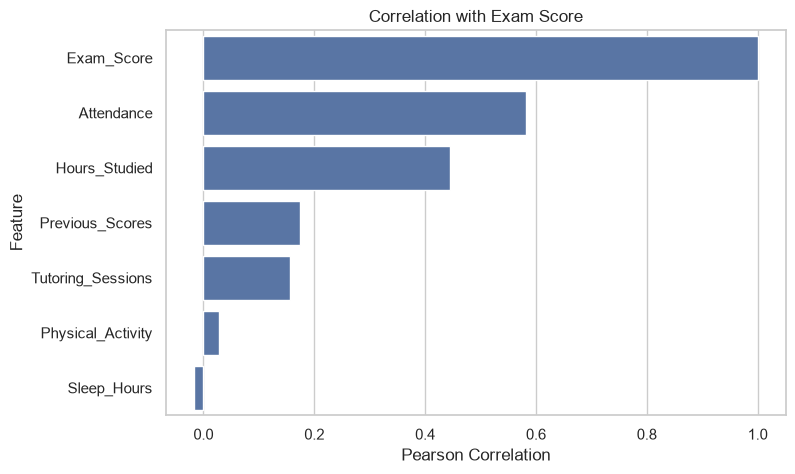

In [15]:
correlation_with_target = (
    df[numerical_columns]
    .corr()["Exam_Score"]
    .sort_values(ascending=False)
)

display(correlation_with_target)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=correlation_with_target.values,
    y=correlation_with_target.index
)

plt.title("Correlation with Exam Score")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")

plt.show()

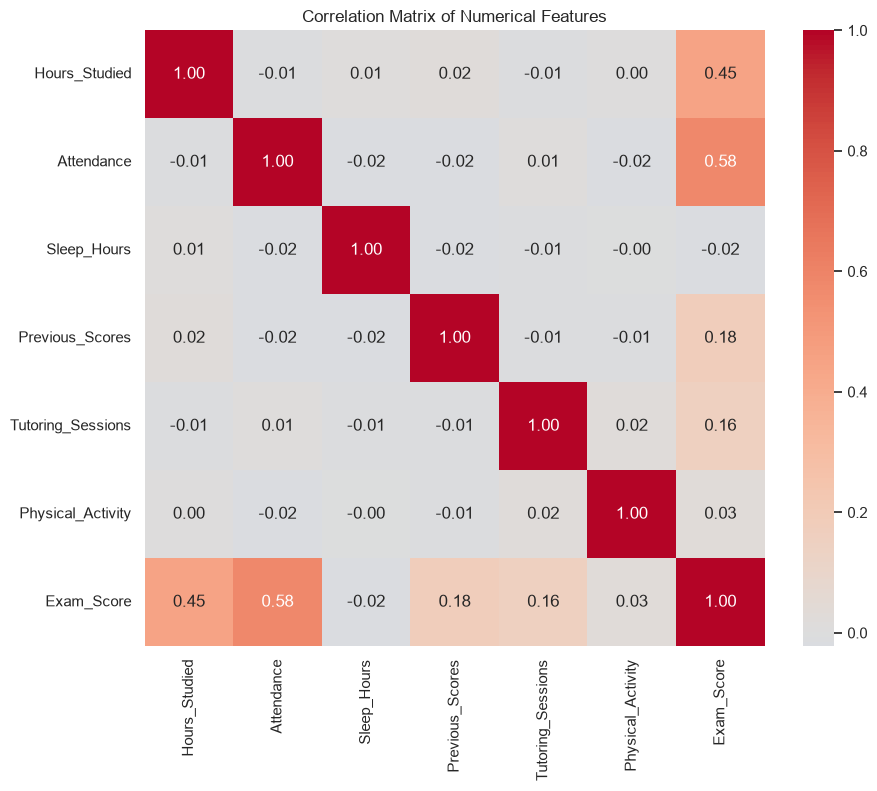

In [16]:
correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")

plt.show()

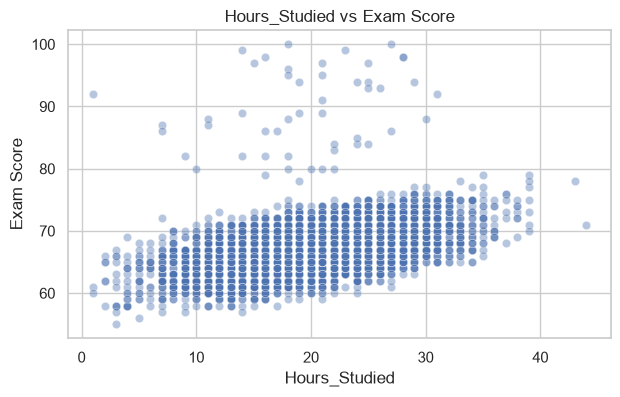

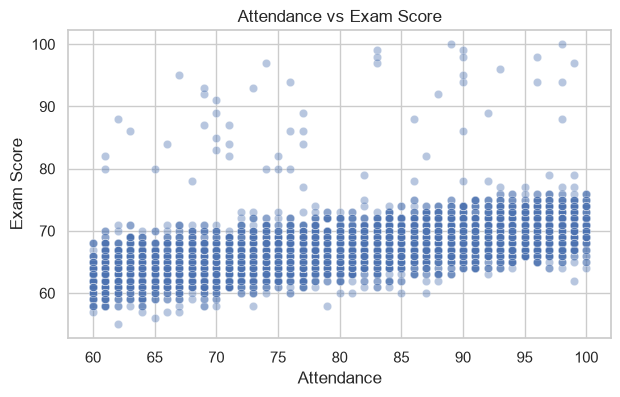

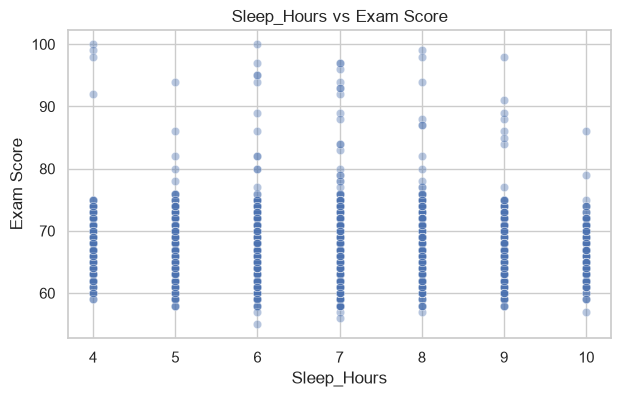

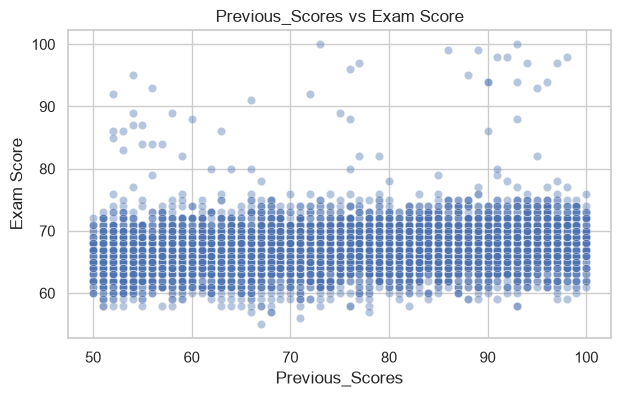

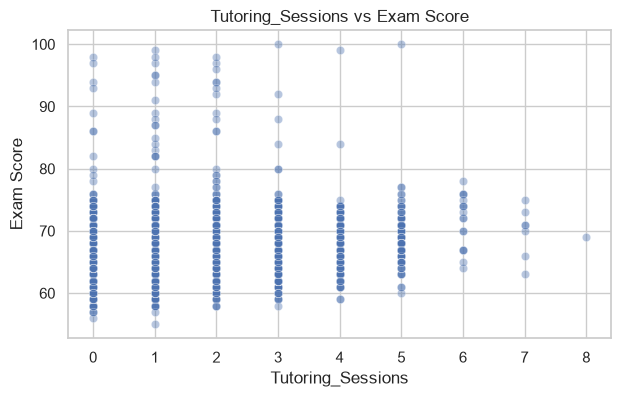

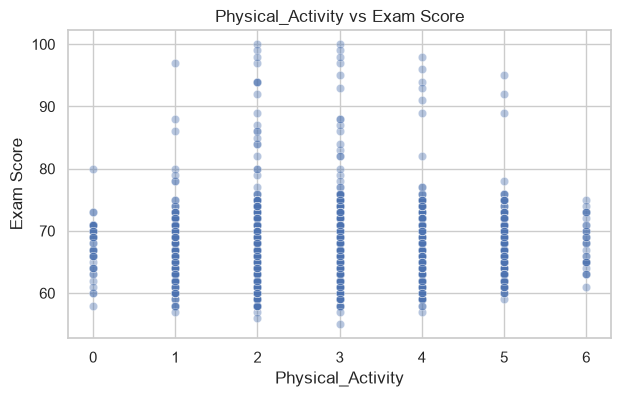

In [17]:
for feature in numerical_predictors:

    plt.figure(figsize=(7, 4))

    sns.scatterplot(
        data=df,
        x=feature,
        y="Exam_Score",
        alpha=0.4
    )

    plt.title(f"{feature} vs Exam Score")
    plt.xlabel(feature)
    plt.ylabel("Exam Score")

    plt.show()

In [18]:
for feature in categorical_columns:

    print(f"\n{feature}")
    display(df[feature].value_counts(dropna=False))


Parental_Involvement


Parental_Involvement
Medium    3362
High      1908
Low       1337
Name: count, dtype: int64


Access_to_Resources


Access_to_Resources
Medium    3319
High      1975
Low       1313
Name: count, dtype: int64


Extracurricular_Activities


Extracurricular_Activities
Yes    3938
No     2669
Name: count, dtype: int64

... (16 outputs left out)


Distance_from_Home


Distance_from_Home
Near        3884
Moderate    1998
Far          658
NaN           67
Name: count, dtype: int64


Gender


Gender
Male      3814
Female    2793
Name: count, dtype: int64

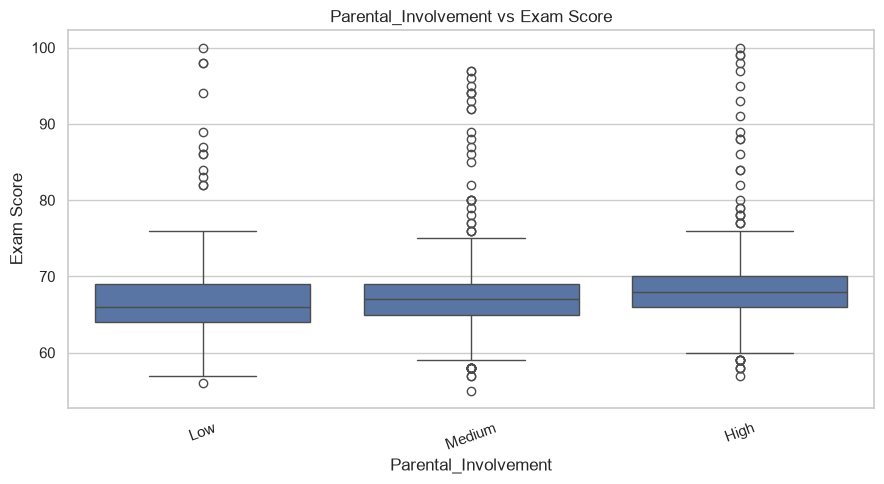

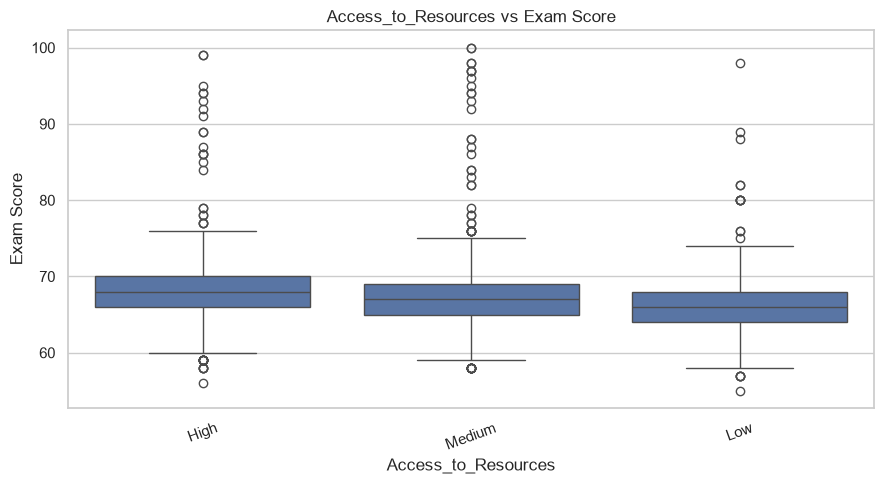

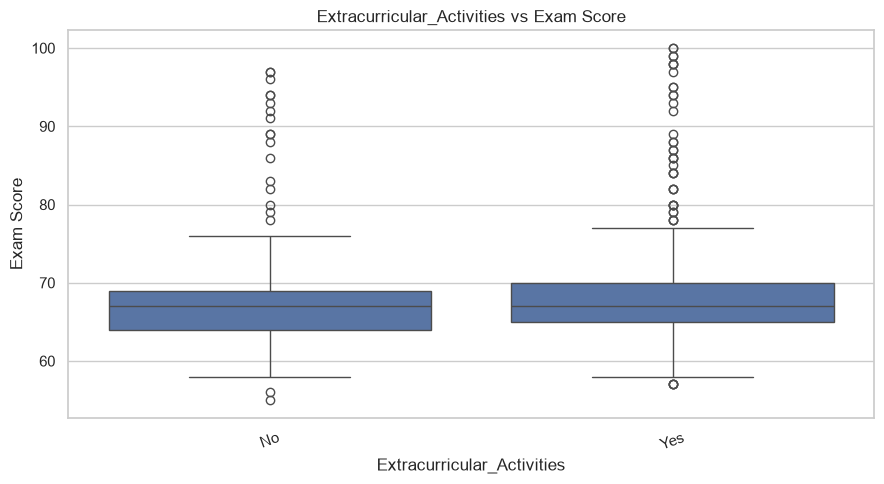

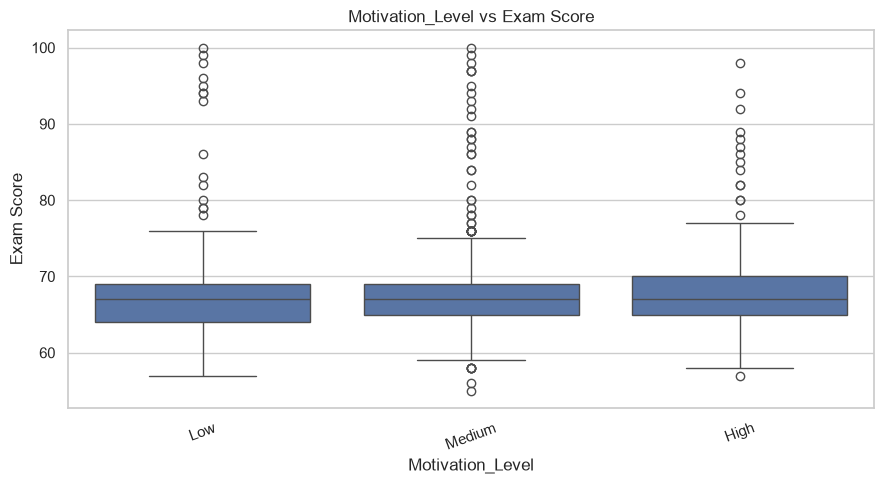

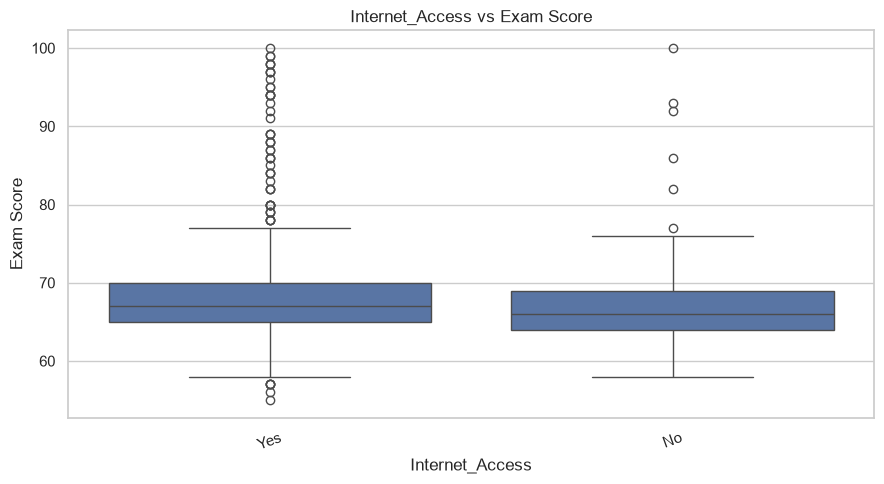

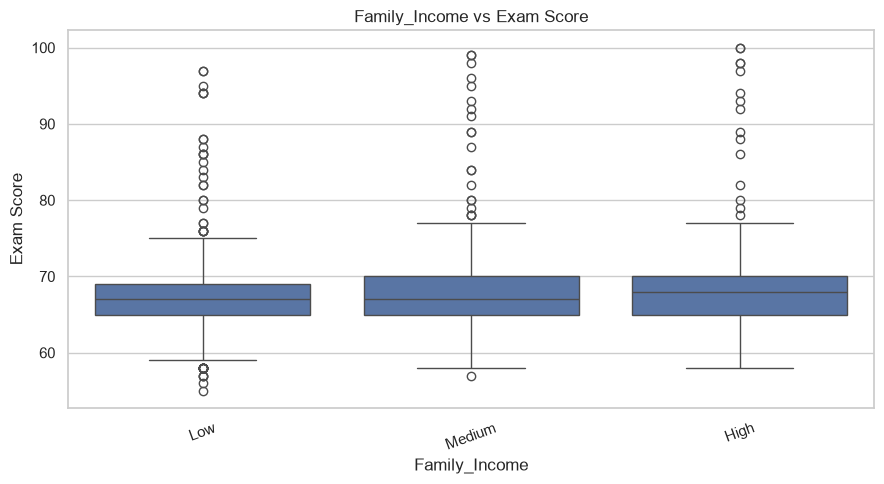

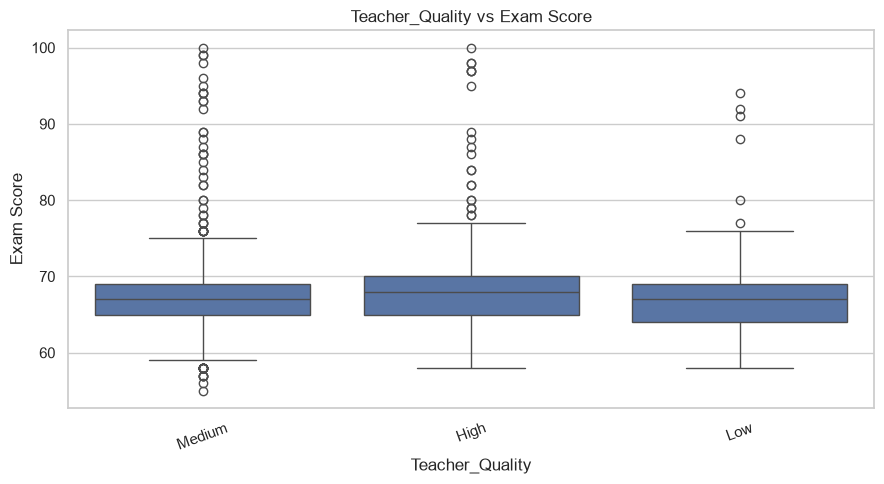

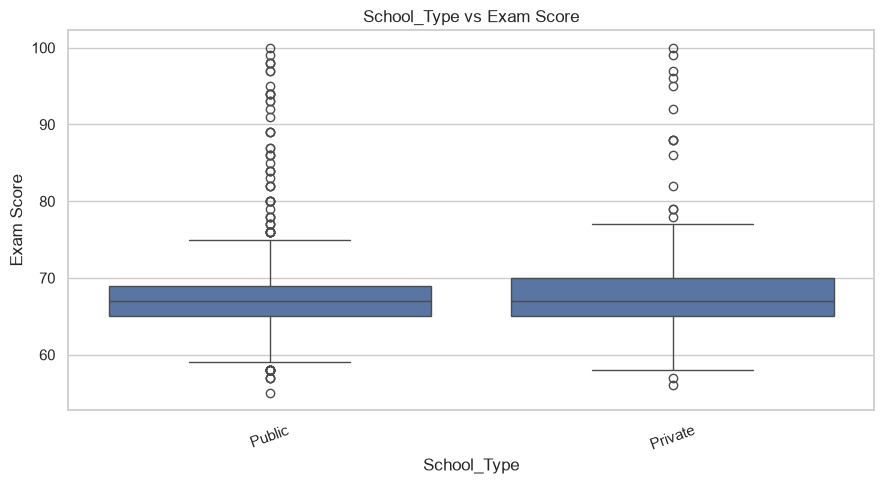

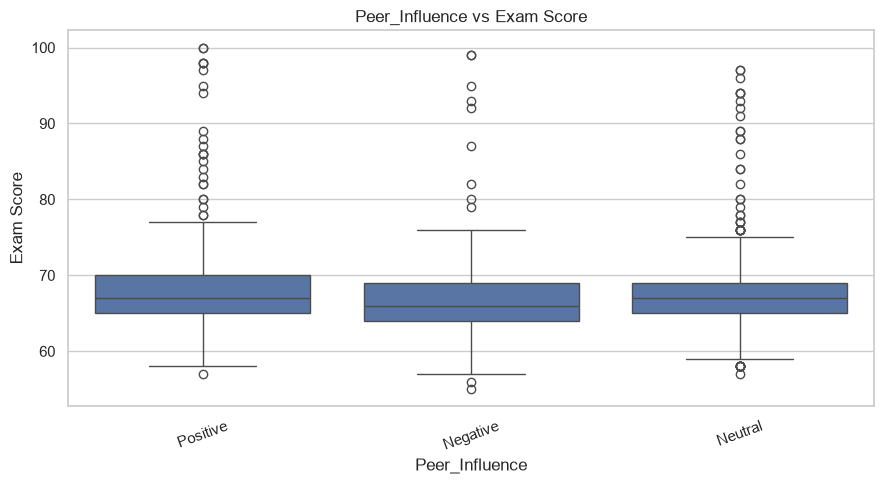

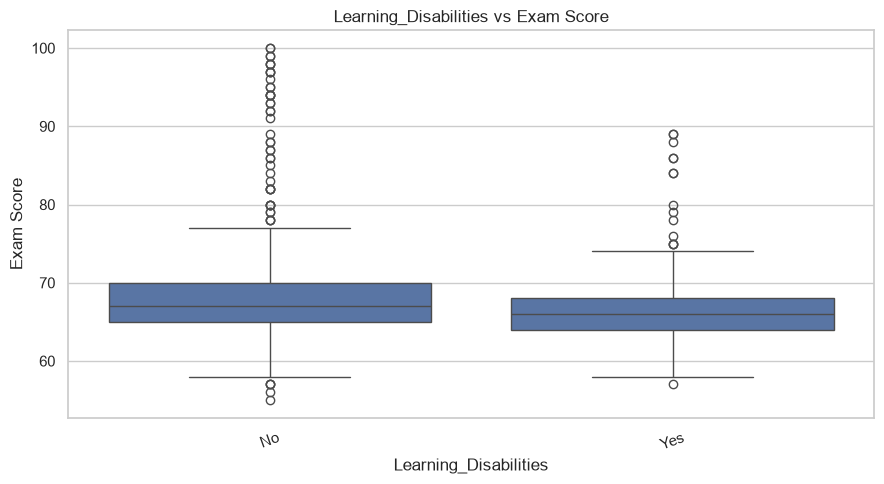

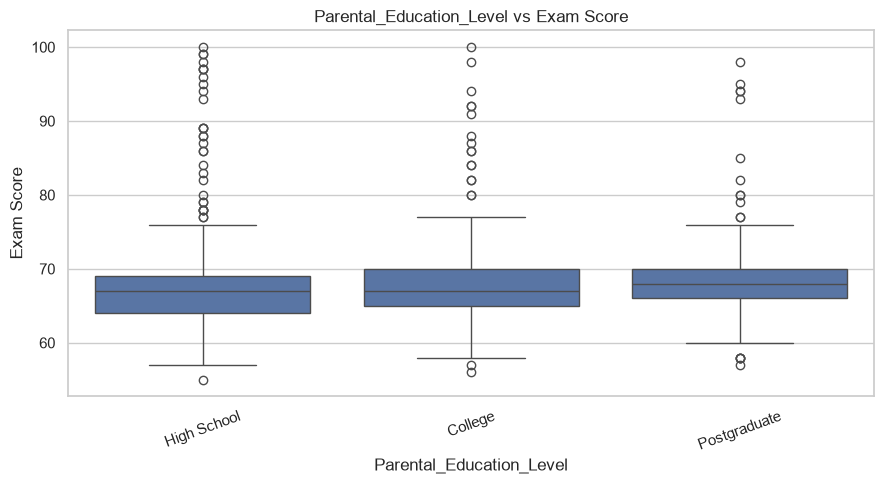

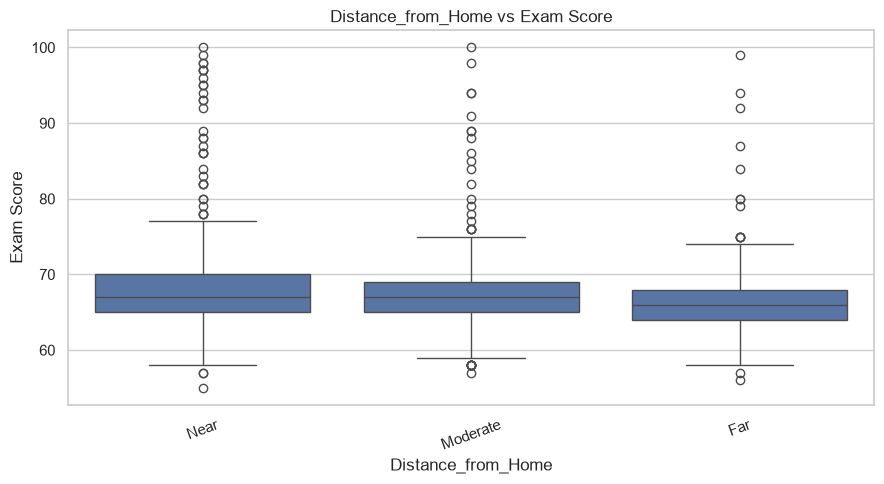

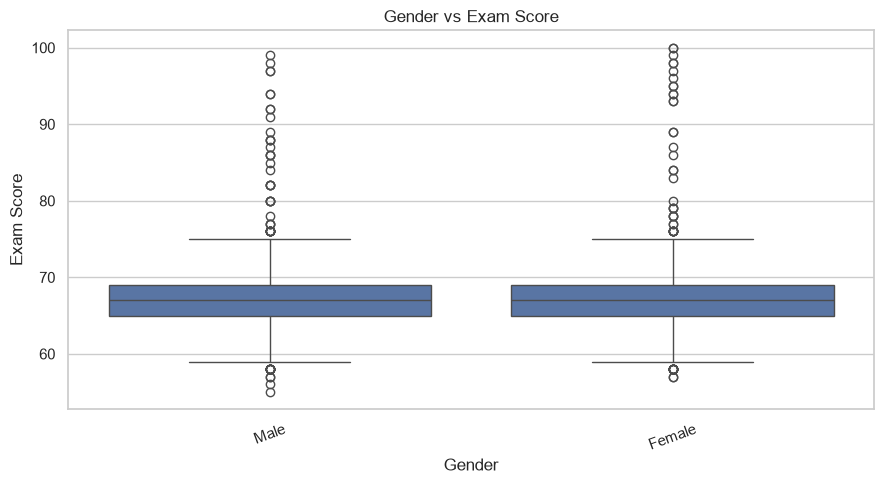

In [19]:
for feature in categorical_columns:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x=feature,
        y="Exam_Score"
    )

    plt.title(f"{feature} vs Exam Score")
    plt.xlabel(feature)
    plt.ylabel("Exam Score")

    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

In [20]:
for feature in categorical_columns:

    print(f"\nAverage Exam Score by {feature}:")

    result = (
        df.groupby(feature, dropna=False)["Exam_Score"]
        .agg(["mean", "count"])
        .sort_values("mean", ascending=False)
    )

    display(result)


Average Exam Score by Parental_Involvement:


,mean,count
Parental_Involvement,,
High,68.092767,1908
Medium,67.098156,3362
Low,66.357517,1337



Average Exam Score by Access_to_Resources:


,mean,count
Access_to_Resources,,
High,68.092152,1975
Medium,67.134077,3319
Low,66.203351,1313



Average Exam Score by Extracurricular_Activities:


,mean,count
Extracurricular_Activities,,
Yes,67.441595,3938
No,66.931435,2669


... (16 outputs left out)


Average Exam Score by Distance_from_Home:


,mean,count
Distance_from_Home,,
Near,67.512101,3884
Moderate,66.980981,1998
Far,66.457447,658
NaN,66.432836,67



Average Exam Score by Gender:


,mean,count
Gender,,
Female,67.244540,2793
Male,67.228894,3814


In [21]:
for feature in [
    "Teacher_Quality",
    "Parental_Education_Level",
    "Distance_from_Home"
]:

    df[f"{feature}_Missing"] = df[feature].isna()

    print(f"\n{feature}")

    display(
        df.groupby(f"{feature}_Missing")["Exam_Score"]
        .agg(["mean", "count"])
    )


Teacher_Quality


,mean,count
Teacher_Quality_Missing,,
False,67.242610,6529
True,66.641026,78



Parental_Education_Level


,mean,count
Parental_Education_Level_Missing,,
False,67.237993,6517
True,67.055556,90



Distance_from_Home


,mean,count
Distance_from_Home_Missing,,
False,67.243731,6540
True,66.432836,67


In [22]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Number of records",
        "Number of original features",
        "Duplicate records",
        "Missing cells",
        "Mean Exam Score",
        "Median Exam Score",
        "Minimum Exam Score",
        "Maximum Exam Score",
        "Standard Deviation of Exam Score"
    ],
    "Value": [
        len(df),
        df.shape[1],
        df.duplicated().sum(),
        df.isnull().sum().sum(),
        df["Exam_Score"].mean(),
        df["Exam_Score"].median(),
        df["Exam_Score"].min(),
        df["Exam_Score"].max(),
        df["Exam_Score"].std()
    ]
})

display(eda_summary)

docs_dir = PROJECT_ROOT / "docs"
docs_dir.mkdir(parents=True, exist_ok=True)
eda_summary.to_csv(
    docs_dir / "AcademiQ_EDA_Summary.csv",
    index=False
)
print("Saved: docs/AcademiQ_EDA_Summary.csv")


,Metric,Value
0,Number of records,6607.000000
1,Number of original features,23.000000
2,Duplicate records,0.000000
3,Missing cells,235.000000
4,Mean Exam Score,67.235508
5,Median Exam Score,67.000000
6,Minimum Exam Score,55.000000
7,Maximum Exam Score,100.000000
8,Standard Deviation of Exam Score,3.889161


Saved: docs/AcademiQ_EDA_Summary.csv


In [23]:
print("EDA summary saved successfully to docs/AcademiQ_EDA_Summary.csv.")


EDA summary saved successfully to docs/AcademiQ_EDA_Summary.csv.


## Exploratory Data Analysis Summary

The exploratory data analysis establishes key dataset characteristics:
- **Dataset Dimensions:** 6,607 student observations with 19 predictor features and 1 target variable (`Exam_Score`).
- **Data Hygiene:** 0 duplicate rows detected. Missing values are confined to three categorical attributes: `Teacher_Quality` (78), `Parental_Education_Level` (90), and `Distance_from_Home` (67).
- **Target Distribution:** Examination scores follow an approximately normal distribution ($\\mu \\approx 67.2$, $\\sigma \\approx 3.9$) bounded between 55 and 100 after clipping the recorded outlier (101).
- **Key Correlates:** `Attendance` ($r \\approx 0.58$) and `Hours_Studied` ($r \\approx 0.45$) show the strongest positive association with academic performance.
- **Downstream Flow:** Outlier adjustment, missing-value imputation, and leakage-safe train/test partitioning are systematically handled in `AcademiQ_02_Preprocessing.ipynb`.
